In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
PROJECT_DIR = Path(
    r"F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
FORECAST_DIR = OUTPUT_DIR / "forecasts"

# Create output directories
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
FORECAST_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = PROCESSED_DIR / "daily_booking_demand.csv"

print("Project path:", PROJECT_DIR)
print("Dataset path:", DATA_PATH)

Project path: F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand
Dataset path: F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\data\processed\daily_booking_demand.csv


In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Run the previous notebooks and create daily_booking_demand.csv."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (335, 2)


,DATE,BOOKING_COUNT
0,2026-01-08,13691.0
1,2026-01-09,NaN
2,2026-01-10,NaN
3,2026-01-11,NaN
4,2026-01-12,NaN


In [10]:

# Identify columns from the dataset
df.columns = df.columns.astype(str).str.strip().str.upper()

date_col = "DATE"
demand_col = "BOOKING_COUNT"

# Validate columns
if date_col not in df.columns:
    raise ValueError(
        f"DATE not found. Available columns: {df.columns.tolist()}"
    )

if demand_col not in df.columns:
    raise ValueError(
        f"BOOKING_COUNT not found. Available columns: {df.columns.tolist()}"
    )

print("Date column:", date_col)
print("Demand column:", demand_col)
print("Column identification successful!")

Date column: DATE
Demand column: BOOKING_COUNT
Column identification successful!


In [11]:
print("Start date:", df[date_col].min())
print("End date:", df[date_col].max())
print("Number of records:", len(df))

expected_dates = pd.date_range(
    start=df[date_col].min(),
    end=df[date_col].max(),
    freq="D"
)

missing_dates = expected_dates.difference(df[date_col])

print("Missing calendar dates:", len(missing_dates))

if len(missing_dates) > 0:
    print("First missing dates:")
    print(missing_dates[:10])

Start date: 2026-01-08
End date: 2026-12-08
Number of records: 335
Missing calendar dates: 335
First missing dates:
DatetimeIndex(['2026-01-08', '2026-01-09', '2026-01-10', '2026-01-11',
               '2026-01-12', '2026-01-13', '2026-01-14', '2026-01-15',
               '2026-01-16', '2026-01-17'],
              dtype='datetime64[ns]', freq='D')


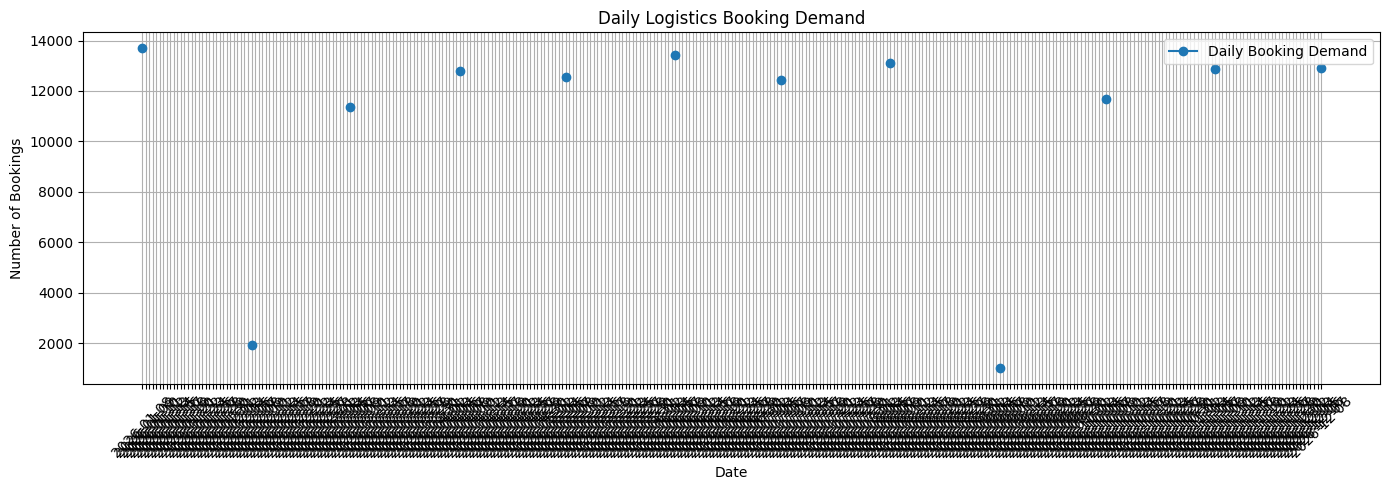

In [12]:
plt.figure(figsize=(14, 5))

plt.plot(
    df[date_col],
    df[demand_col],
    marker="o",
    linewidth=1.5,
    label="Daily Booking Demand"
)

plt.title("Daily Logistics Booking Demand")
plt.xlabel("Date")
plt.ylabel("Number of Bookings")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "baseline_daily_booking_demand.png",
    dpi=300
)

plt.show()

In [13]:
split_index = int(len(df) * 0.8)

train = df.iloc[:split_index].copy()
test = df.iloc[split_index:].copy()

if len(train) == 0 or len(test) == 0:
    raise ValueError(
        "Not enough data for a train-test split."
    )

print("Training records:", len(train))
print("Testing records:", len(test))

print("\nTraining period:")
print(train[date_col].min(), "to", train[date_col].max())

print("\nTesting period:")
print(test[date_col].min(), "to", test[date_col].max())

Training records: 268
Testing records: 67

Training period:
2026-01-08 to 2026-10-02

Testing period:
2026-10-03 to 2026-12-08


In [14]:
actual_demand = test[demand_col].to_numpy()

previous_demand = df[demand_col].iloc[
    split_index - 1 : len(df) - 1
].to_numpy()

naive_predictions = previous_demand

test_results = pd.DataFrame({
    date_col: test[date_col].to_numpy(),
    "actual": actual_demand,
    "naive_forecast": naive_predictions
})

print("Naive forecast created successfully!")

display(test_results.head())

Naive forecast created successfully!


,DATE,actual,naive_forecast
0,2026-10-03,NaN,NaN
1,2026-10-04,NaN,NaN
2,2026-10-05,NaN,NaN
3,2026-10-06,NaN,NaN
4,2026-10-07,NaN,NaN


In [16]:

# Convert date columns to datetime
df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
train[date_col] = pd.to_datetime(train[date_col], errors="coerce")
test[date_col] = pd.to_datetime(test[date_col], errors="coerce")

# Remove rows with invalid dates
df = df.dropna(subset=[date_col]).copy()
train = train.dropna(subset=[date_col]).copy()
test = test.dropna(subset=[date_col]).copy()

# Ensure dates are sorted
df = df.sort_values(date_col).reset_index(drop=True)
train = train.sort_values(date_col).reset_index(drop=True)
test = test.sort_values(date_col).reset_index(drop=True)

# Seasonal naive forecasting (7-day seasonality)
seasonal_predictions = []

for date in test[date_col]:
    previous_week_date = date - pd.Timedelta(days=7)

    previous_week_value = df.loc[
        df[date_col] == previous_week_date,
        demand_col
    ]

    if not previous_week_value.empty:
        prediction = previous_week_value.iloc[0]
    else:
        previous_day_date = date - pd.Timedelta(days=1)

        previous_day_value = df.loc[
            df[date_col] == previous_day_date,
            demand_col
        ]

        if not previous_day_value.empty:
            prediction = previous_day_value.iloc[0]
        else:
            prediction = train[demand_col].iloc[-1]

    seasonal_predictions.append(prediction)

# Store predictions
test_results["seasonal_naive_forecast"] = seasonal_predictions

print("Seasonal naive forecast created successfully!")

display(test_results.head())

Seasonal naive forecast created successfully!


,DATE,actual,naive_forecast,seasonal_naive_forecast
0,2026-10-03,NaN,NaN,NaN
1,2026-10-04,NaN,NaN,NaN
2,2026-10-05,NaN,NaN,NaN
3,2026-10-06,NaN,NaN,NaN
4,2026-10-07,NaN,NaN,NaN


In [17]:
moving_average_predictions = []

for date in test[date_col]:
    history = df.loc[
        df[date_col] < date,
        demand_col
    ].tail(7)

    if len(history) > 0:
        prediction = history.mean()
    else:
        prediction = train[demand_col].mean()

    moving_average_predictions.append(prediction)

test_results["moving_average_forecast"] = (
    moving_average_predictions
)

print("Moving average forecast created successfully!")

display(test_results.head())

Moving average forecast created successfully!


,DATE,actual,naive_forecast,seasonal_naive_forecast,moving_average_forecast
0,2026-10-03,NaN,NaN,NaN,NaN
1,2026-10-04,NaN,NaN,NaN,NaN
2,2026-10-05,NaN,NaN,NaN,NaN
3,2026-10-06,NaN,NaN,NaN,NaN
4,2026-10-07,NaN,NaN,NaN,NaN


In [18]:
def calculate_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    nonzero_mask = actual != 0

    if nonzero_mask.any():
        mape = np.mean(
            np.abs(
                (actual[nonzero_mask] - predicted[nonzero_mask])
                / actual[nonzero_mask]
            )
        ) * 100
    else:
        mape = np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }

print("Evaluation function created!")

Evaluation function created!


In [20]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Function to calculate evaluation metrics
def calculate_metrics(actual, predicted):
    # Convert values to numeric
    actual = pd.to_numeric(actual, errors="coerce")
    predicted = pd.to_numeric(predicted, errors="coerce")

    # Keep only rows where both values are valid
    valid = actual.notna() & predicted.notna()
    actual = actual[valid].to_numpy()
    predicted = predicted[valid].to_numpy()

    if len(actual) == 0:
        return {
            "MAE": np.nan,
            "RMSE": np.nan,
            "MAPE (%)": np.nan,
            "Samples": 0
        }

    # Calculate metrics
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    # Avoid division by zero in MAPE
    nonzero = actual != 0

    if nonzero.any():
        mape = np.mean(
            np.abs(
                (actual[nonzero] - predicted[nonzero])
                / actual[nonzero]
            )
        ) * 100
    else:
        mape = np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "Samples": len(actual)
    }


# Evaluate all baseline models
actual = test_results["actual"]

naive_metrics = calculate_metrics(
    actual,
    test_results["naive_forecast"]
)

seasonal_metrics = calculate_metrics(
    actual,
    test_results["seasonal_naive_forecast"]
)

moving_average_metrics = calculate_metrics(
    actual,
    test_results["moving_average_forecast"]
)

# Create comparison table
comparison = pd.DataFrame(
    {
        "Naive": naive_metrics,
        "Seasonal Naive": seasonal_metrics,
        "Moving Average": moving_average_metrics
    }
).T

comparison.index.name = "Model"

print("Baseline model evaluation completed!")
display(comparison.round(3))

Baseline model evaluation completed!


,MAE,RMSE,MAPE (%),Samples
Model,,,,
Naive,NaN,NaN,NaN,0.0
Seasonal Naive,NaN,NaN,NaN,0.0
Moving Average,NaN,NaN,NaN,0.0


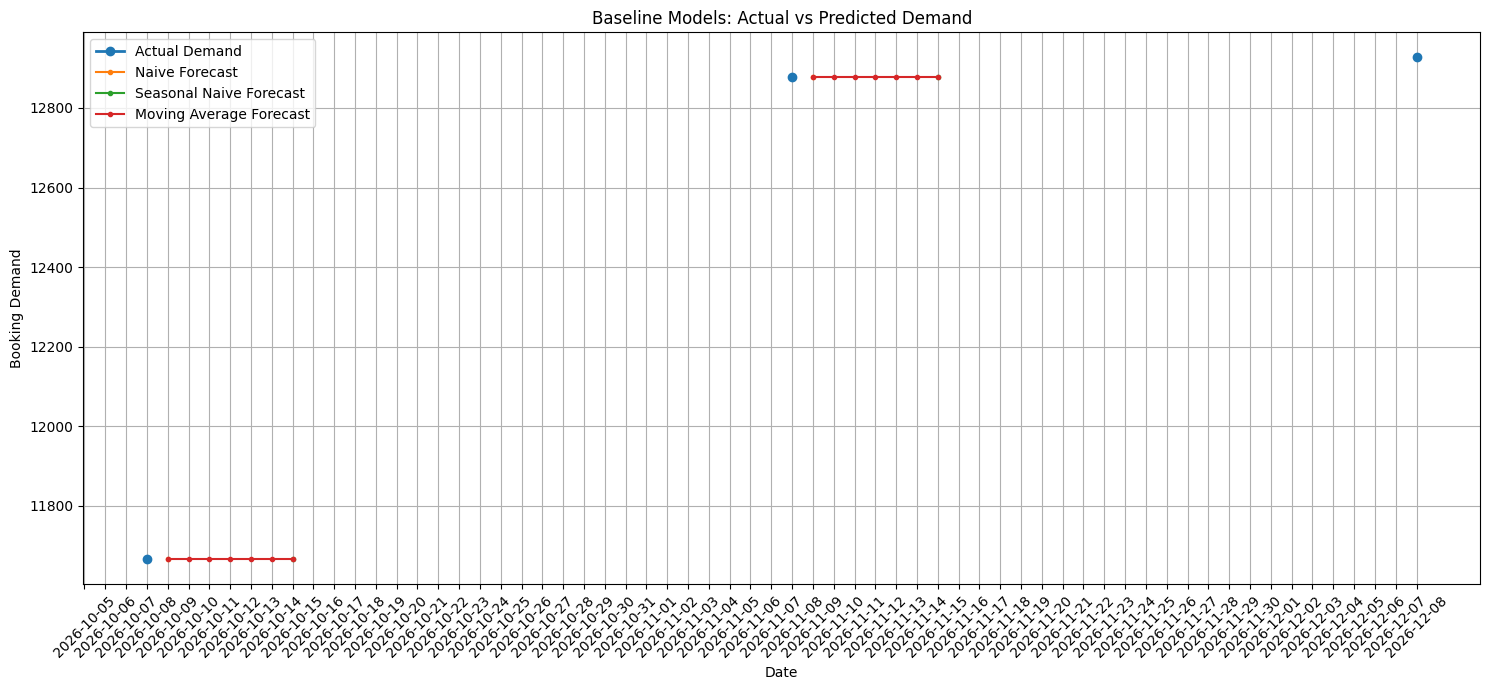

In [21]:
plt.figure(figsize=(15, 7))

plt.plot(
    test_results[date_col],
    test_results["actual"],
    marker="o",
    linewidth=2,
    label="Actual Demand"
)

plt.plot(
    test_results[date_col],
    test_results["naive_forecast"],
    marker=".",
    label="Naive Forecast"
)

plt.plot(
    test_results[date_col],
    test_results["seasonal_naive_forecast"],
    marker=".",
    label="Seasonal Naive Forecast"
)

plt.plot(
    test_results[date_col],
    test_results["moving_average_forecast"],
    marker=".",
    label="Moving Average Forecast"
)

plt.title("Baseline Models: Actual vs Predicted Demand")
plt.xlabel("Date")
plt.ylabel("Booking Demand")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "baseline_model_comparison.png",
    dpi=300
)

plt.show()

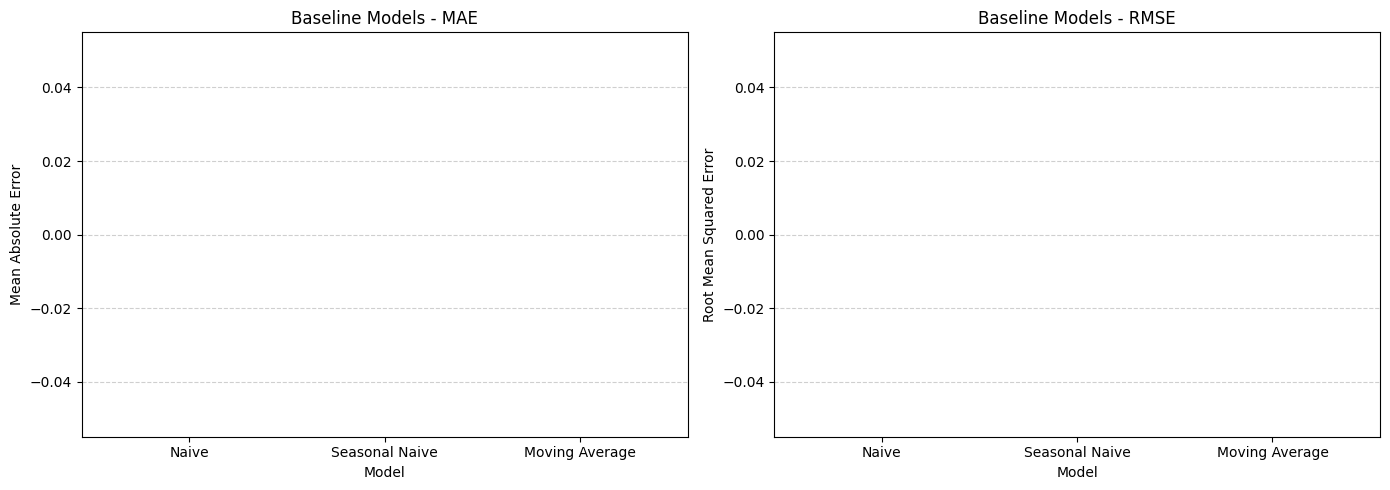

In [23]:

import matplotlib.pyplot as plt

# Create two separate graphs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MAE comparison
comparison["MAE"].plot(
    kind="bar",
    ax=axes[0],
    width=0.6
)

axes[0].set_title("Baseline Models - MAE")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Mean Absolute Error")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", linestyle="--", alpha=0.6)

# RMSE comparison
comparison["RMSE"].plot(
    kind="bar",
    ax=axes[1],
    width=0.6
)

axes[1].set_title("Baseline Models - RMSE")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Root Mean Squared Error")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()

# Save graph
plt.savefig(
    FIGURE_DIR / "baseline_error_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
print(comparison[["MAE", "RMSE"]].to_string())

                MAE  RMSE
Model                    
Naive           NaN   NaN
Seasonal Naive  NaN   NaN
Moving Average  NaN   NaN


In [25]:
test_results["naive_error"] = (
    test_results["actual"]
    - test_results["naive_forecast"]
)

test_results["seasonal_naive_error"] = (
    test_results["actual"]
    - test_results["seasonal_naive_forecast"]
)

test_results["moving_average_error"] = (
    test_results["actual"]
    - test_results["moving_average_forecast"]
)

display(test_results.head(10))

,DATE,actual,naive_forecast,seasonal_naive_forecast,moving_average_forecast,naive_error,seasonal_naive_error,moving_average_error
0,2026-10-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-10-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-10-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-10-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-10-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2026-10-08,11667.0,NaN,NaN,NaN,NaN,NaN,NaN
6,2026-10-09,NaN,11667.0,NaN,11667.0,NaN,NaN,NaN
7,2026-10-10,NaN,NaN,NaN,11667.0,NaN,NaN,NaN
8,2026-10-11,NaN,NaN,NaN,11667.0,NaN,NaN,NaN
9,2026-10-12,NaN,NaN,NaN,11667.0,NaN,NaN,NaN


In [26]:
PREDICTIONS_PATH = (
    FORECAST_DIR / "baseline_predictions.csv"
)

test_results.to_csv(
    PREDICTIONS_PATH,
    index=False
)

print("Baseline predictions saved successfully!")
print("File:", PREDICTIONS_PATH)

Baseline predictions saved successfully!
File: F:\AI-Driven Time-Series Forecasting and Predictive Analytics for Logistics Booking Demand\outputs\forecasts\baseline_predictions.csv
